In [1]:
import os
import random

# add current directory to path
import sys

sys.path.append(os.path.dirname(os.getcwd()))

from evaluation.analysis_helper import (
    compute_optimal_picked_instances,
    get_dataframes_from_run,
)

import wandb

api = wandb.Api()

# wandb_project = "learneddb/lcm"
wandb_project = "learneddb/white_mamba"
if os.path.exists("wandb_df_cache.pkl"):
    import pickle

    with open("wandb_df_cache.pkl", "rb") as f:
        df_cache = pickle.load(f)
else:
    raise FileNotFoundError(
        "wandb_df_cache.pkl not found. Are you really sure that there is no cache?"
    )
    df_cache = dict()

In [2]:
runs = [
    # '8tn6ih3o',
    # 'vyuutioc',
    # 'ivqkjj6c',
    # 'o3vdkq0c',
    # '3w89oh35',
    # '7wfuqhla'
    # 'uq3o7vip',
    # 'hfodlkxt',
    # '6d3st30c',
    # 'cj7nu19q',
    # '2d8o4b32',
    # "kn95yj0r",  # stealth
    "h1anmvrh"
]
run_dict = dict()
for run in runs:
    run_dict[run] = get_dataframes_from_run(
        run, df_cache, api, skip_cache=False, wandb_project=wandb_project
    )

Found run h1anmvrh in cache


In [3]:
run = runs[0]

dataset = "job_extended"

if dataset == "job":
    df = run_dict[run]["join_order_job_eval_pred_table"]
elif dataset == "job_extended":
    df = run_dict[run]["join_order_job_extended_eval_pred_table"]
else:
    raise ValueError(f"Unknown dataset {dataset}")

opt_runtimes, picked_runtimes, opt_plan_instances, picked_plan_instances, sqls = (
    compute_optimal_picked_instances(df)
)

print(f"Optimal runtime: {sum(opt_runtimes)}")
print(f"Picked runtime: {sum(picked_runtimes)}")

Optimal runtime: 54.1722539588809
Picked runtime: 447.7710797190666


## Plot JOB Speedup Overview

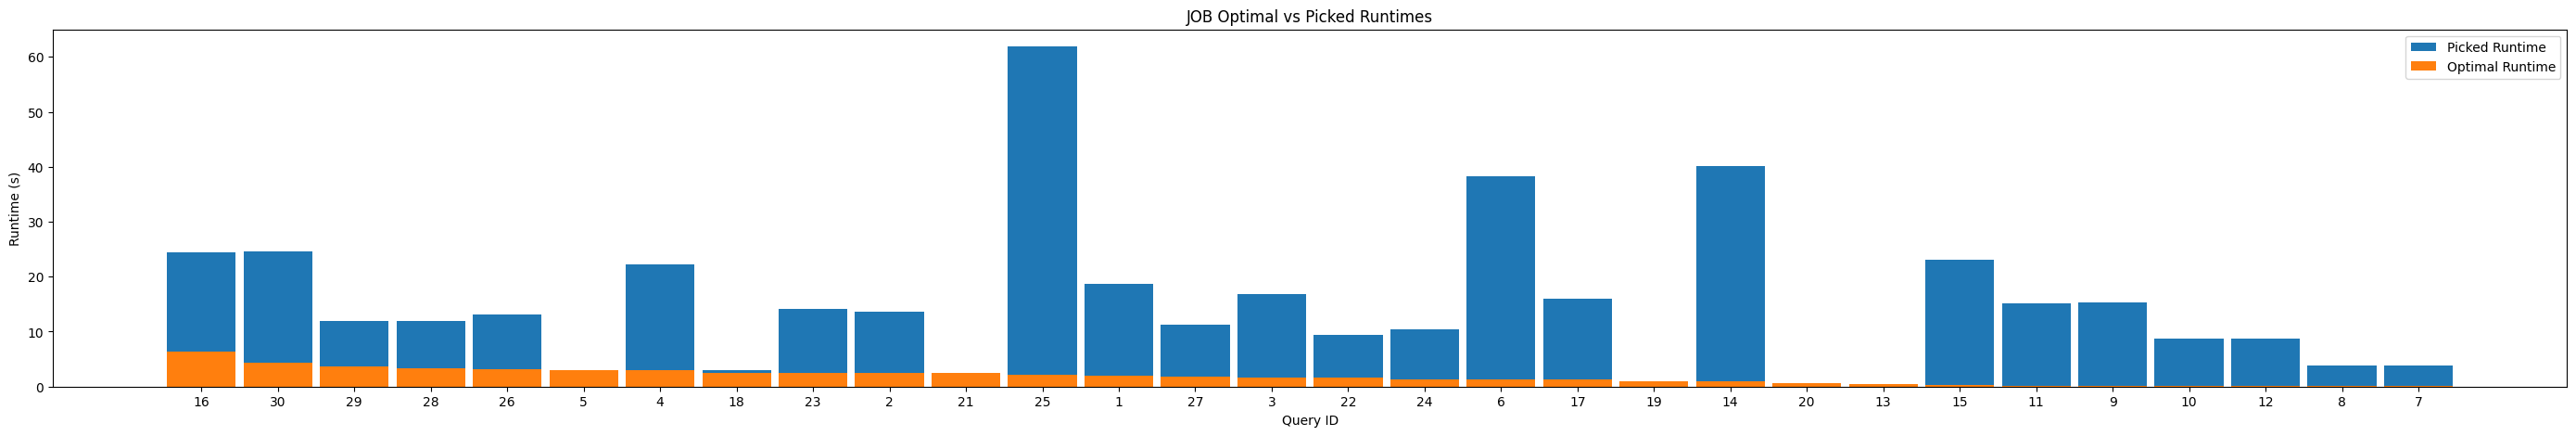

In [4]:
# plot barchart with selected runtime and optimal runtime for each query
import matplotlib.pyplot as plt

q_id = [i for i in range(len(opt_runtimes))]

# sort by opt runtime
sorted_indices = [
    i
    for i in sorted(
        range(len(opt_runtimes)), key=lambda k: opt_runtimes[k], reverse=True
    )
]
opt_runtimes_sorted = [opt_runtimes[i] for i in sorted_indices]
picked_runtimes_sorted = [picked_runtimes[i] for i in sorted_indices]
q_id_sorted = [q_id[i] + 1 for i in sorted_indices]

plt.figure(figsize=(35, 5))
bar_width = 0.9
indices = range(len(opt_runtimes))
plt.bar(indices, picked_runtimes_sorted, width=bar_width, label="Picked Runtime")
plt.bar(indices, opt_runtimes_sorted, width=bar_width, label="Optimal Runtime")
plt.xticks([i for i in indices], q_id_sorted)
plt.legend()
plt.xlabel("Query ID")
plt.ylabel("Runtime (s)")
plt.title("JOB Optimal vs Picked Runtimes")
plt.show()

In [5]:
import json

with open(
    "/home/johannes/ldb/ldb_wlexecutor/src/ldb_wlexecutor/analysis/job_analysis.json",
    "r",
) as f:
    job_analysis = json.load(f)


# compute dict mapping job sql query to stats
def extract_info_dicts(analysis):
    query_info = dict()
    query_info_by_id = dict()
    for q in analysis:
        sql = q["query_string"]

        # remove newlines and tabs
        sql = sql.replace("\n", " ").replace("\t", " ")

        # remove all multiple whitespaces
        sql = " ".join(sql.split())

        query_info[sql] = q
        query_info_by_id[str(q["query_id"])] = q

    return query_info, query_info_by_id


job_query_info, job_query_info_by_id = extract_info_dicts(job_analysis)

In [6]:
import matplotlib
from ipywidgets import interact


@interact(
    metric=["dif", "speedup"],
    highlight=[
        "num_tables",
        "num_simple_numeric_filters",
        "num_simple_string_filters",
        "num_in_filters",
        "num_like_filters",
        "null_filters",
        "max_filters_per_table",
    ],
)
def plot(highlight: str = None, metric: str = "dif"):
    q_id = [i for i in range(len(opt_runtimes))]

    # sort by opt runtime
    sorted_indices = [
        i
        for i in sorted(
            range(len(opt_runtimes)), key=lambda k: opt_runtimes[k], reverse=True
        )
    ]
    opt_runtimes_sorted = [opt_runtimes[i] for i in sorted_indices]
    picked_runtimes_sorted = [picked_runtimes[i] for i in sorted_indices]
    sql_sorted = [sqls[i] for i in sorted_indices]

    if metric == "dif":
        slowdowns = [
            picked - opt
            for picked, opt in zip(picked_runtimes_sorted, opt_runtimes_sorted)
        ]
    else:
        slowdowns = [
            picked / opt
            for picked, opt in zip(picked_runtimes_sorted, opt_runtimes_sorted)
        ]
    q_id_sorted = [q_id[i] + 1 for i in sorted_indices]

    colors = None
    if highlight is not None:
        colorize_key = [job_query_info[sql][highlight] for sql in sql_sorted]

        # create color map
        cmap = matplotlib.colormaps.get_cmap("autumn_r")
        norm = matplotlib.colors.Normalize(
            vmin=min(colorize_key), vmax=max(colorize_key)
        )
        colors = cmap(norm(colorize_key))

    # create barchart
    plt.close()
    fig, ax = plt.subplots(figsize=(35, 5))
    bar_width = 0.9
    indices = range(len(opt_runtimes))
    ax.bar(
        indices,
        slowdowns,
        width=bar_width,
        label="Picked Runtime",
        color=colors if colors is not None else "c",
    )
    ax.set_xticks([i for i in indices], q_id_sorted)
    plt.legend()
    plt.xlabel("Query ID")
    plt.ylabel("Runtime (s)" if metric == "dif" else "Slowdown")

    if highlight is not None:
        # Add a colorbar for reference
        sm = matplotlib.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax)
        cbar.set_label(highlight)

    plt.title("JOB Optimal vs Picked Runtimes")
    plt.show()

interactive(children=(Dropdown(description='highlight', options=('num_tables', 'num_simple_numeric_filters', '…

In [7]:
plot("num_tables", "dif")

KeyError: "SELECT MIN(cn.name) AS movie_company, MIN(mi_idx.info) AS rating, MIN(t.title) AS western_violent_movie FROM company_name AS cn, company_type AS ct, info_type AS it1, info_type AS it2, keyword AS k, kind_type AS kt, movie_companies AS mc, movie_info AS mi, movie_info_idx AS mi_idx, movie_keyword AS mk, title AS t, aka_name AS ak, char_name AS ch, name AS n WHERE cn.country_code != '[us]' AND it1.info = 'countries' AND it2.info = 'rating' AND k.keyword IN ('murder', 'murder-in-title', 'blood', 'violence') AND kt.kind IN ('movie', 'episode') AND mc.note NOT LIKE '%(USA)%' AND mc.note LIKE '%(200%)%' AND mi.info IN ('Germany', 'German', 'USA', 'American') AND mi_idx.info < '7.0' AND t.production_year > 2009 AND kt.id = t.kind_id AND t.id = mi.movie_id AND t.id = mk.movie_id AND t.id = mi_idx.movie_id AND t.id = mc.movie_id AND mk.movie_id = mi.movie_id AND mk.movie_id = mi_idx.movie_id AND mk.movie_id = mc.movie_id AND mi.movie_id = mi_idx.movie_id AND mi.movie_id = mc.movie_id

### Add to wandb run

In [ ]:
append_to_wandb = False
if append_to_wandb:
    print("Picked:")
    print(picked_runtimes_sorted[:10])
    print("Optimal:")
    print(opt_runtimes_sorted[:10])

    wandb_run = wandb.init(entity="learneddb", project="lcm", id=run, resume="must")
    wandb_run.log(
        {
            "join_order_job_eval_plot": wandb.plot.line_series(
                xs=range(len(opt_runtimes)),
                ys=[opt_runtimes_sorted, picked_runtimes_sorted],
                keys=["Optimal Runtimes", "Picked Runtimes"],
                title="JOB - Picked vs. Optimal Runtimes",
                xname="Query ID",
            ),
        }
    )

## Print Info about query with largest potential

In [7]:
from evaluation.analysis_helper import create_explain_dalibo_entry, search_plan
from tabulate import tabulate

# find idx with highest absolute error
absolute_slowdown = [picked - opt for picked, opt in zip(picked_runtimes, opt_runtimes)]
max_idx = absolute_slowdown.index(max(absolute_slowdown))

print(f"Max absolute slowdown: {absolute_slowdown[max_idx]:.2f}s ({max_idx})")

opt_p = opt_plan_instances[max_idx]
picked_p = picked_plan_instances[max_idx]

# find matching plan
opt_plans, opt_plans_parsed = search_plan(opt_p["sql"], opt_p["hint"], dataset=dataset)
picked_plans, picked_plans_parsed = search_plan(
    picked_p["sql"], picked_p["hint"], dataset=dataset
)

assert len(opt_plans) == 1
assert len(picked_plans) == 1

# create dalibo entries
random_id = random.randint(0, 1000)

create_dalibo = True
if create_dalibo:
    opt_url = create_explain_dalibo_entry(
        opt_p["sql"], opt_plans[0]["analyze_plans"][0], f"{random_id}_Optimal"
    )
    picked_url = create_explain_dalibo_entry(
        picked_p["sql"], picked_plans[0]["analyze_plans"][0], f"{random_id}_Picked"
    )
else:
    opt_url = "not created"
    picked_url = "not created"

# print stuff
print(opt_p["sql"])
header = ["Val", "Optimal", "Picked"]
tabulate_rows = [
    ["Runtime", opt_p["label"], picked_p["label"]],
    ["Prediction", opt_p["prediction"], picked_p["prediction"]],
    ["Absolute Slowdown", "-", absolute_slowdown[max_idx]],
    ["Relative Slowdown", "-", picked_p["label"] / opt_p["label"]],
    ["Hint", opt_p["hint"][:20], picked_p["hint"]][:20],
    ["Dalibo", opt_url, picked_url],
]
print(tabulate(tabulate_rows, headers=header))

Max absolute slowdown: 59.80s (24)
Loading job file imdb_scaled1/JOBExtended_selection1.json
Loaded parsed job file imdb_scaled1/JOBExtended_selection1.json
SELECT MIN(mi.info) AS movie_budget, MIN(mi_idx.info) AS movie_votes, MIN(t.title) AS movie_title FROM cast_info AS ci, info_type AS it1, info_type AS it2, movie_info AS mi, movie_info_idx AS mi_idx, name AS n, title AS t, company_name AS cn WHERE ci.note IN ('(producer)', '(executive producer)') AND it1.info = 'budget' AND it2.info = 'votes' AND n.gender = 'm' AND n.name LIKE '%Tim%' AND t.id = mi.movie_id AND t.id = mi_idx.movie_id AND t.id = ci.movie_id AND ci.movie_id = mi.movie_id AND ci.movie_id = mi_idx.movie_id AND mi.movie_id = mi_idx.movie_id AND n.id = ci.person_id AND it1.id = mi.info_type_id AND it2.id = mi_idx.info_type_id AND cn.name_pcode_nf = n.surname_pcode AND cn.name_pcode_sf = n.surname_pcode;
Val                Optimal                                           Picked
-----------------  ------------------------

In [ ]:
print(json.dumps(picked_plans_parsed[0], indent=2))

{
  "plan_parameters": {
    "act_card": 1,
    "act_time": 25281.04,
    "act_loops": 1,
    "est_card": 1,
    "est_width": 32,
    "pg_cost": 30004623508.39,
    "est_loops": 1,
    "op_name": "Simple Aggregate",
    "output_columns": [
      {
        "aggregation": "MIN",
        "columns": [
          {
            "col_id": 58,
            "child_ref": null,
            "table_name": "title",
            "table_alias": "t",
            "col_name": "title"
          }
        ],
        "udf_name": null,
        "udf_output": "False",
        "child_ref": false
      }
    ],
    "act_children_card": 33,
    "est_children_card": 1,
    "above_udf_filter": false,
    "is_udf_filter": false
  },
  "children": [
    {
      "plan_parameters": {
        "act_card": 33,
        "act_time": 25280.952,
        "act_loops": 1,
        "est_card": 1,
        "est_width": 17,
        "pg_cost": 30004623508.38,
        "est_loops": 1,
        "join": {
          "table_name1": "kind_type",
